# 02 Data Cleaning

**Project:** CreditLens, SME credit risk scoring for guaranteed loans
**CRISP-DM phase:** Data Preparation (brief stage 3: data cleaning)
**Author:** Salem Adel Salem Alshamlan Almarri

**Purpose.** Notebook 01 found 25 data quality issues and planned a fix for each. Here we apply those fixes one step at a time with the functions in `src/cleaning.py`, show the evidence before and after each step, and explain every decision together with the alternative we rejected. The same functions are imported by the Streamlit app, so the app cleans an input loan exactly as the training data was cleaned.

**Inputs:** `data/raw/SBAnational.csv`.

**Outputs:** `data/processed/loans_clean.parquet`, `docs/cleaning_log.md`, `docs/quality_before_after.csv` and figures `docs/figures/fig02_*.png`.

## 1. Setup

As in notebook 01, we add the repository root to the path and take every location from `src/config.py`.

In [1]:
import sys
from datetime import date
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import config
from src import cleaning as cl

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
})
P = config.PALETTE
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
config.PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)


def save_fig(fig, name):
    """Save a figure to docs/figures at 150 dpi and print the relative path."""
    path = config.FIGURES_DIR / name
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Saved {path.relative_to(config.PROJECT_ROOT)}")


def rel(path):
    """Path relative to the repository root, for printing."""
    return path.relative_to(config.PROJECT_ROOT)

## 2. Load the raw data

We read the CSV once. The raw table stays in memory until the end so that the before and after quality tables are computed on exactly the same input.

In [2]:
raw = cl.load_raw(config.RAW_DATA_PATH)
print(f"Loaded {rel(config.RAW_DATA_PATH)}: {raw.shape[0]:,} rows, {raw.shape[1]} columns")

Loaded data/raw/SBAnational.csv: 899,164 rows, 27 columns


## 3. Order of the steps

The order matters. We first fix types, because nothing else can be checked on text. Next we remove rows (unknown outcome, near-duplicates) so that every percentile and median used later is computed on the loans we actually keep. Then we recode, run the logical checks, treat outliers and finally fill missing text. `clean_raw()` runs the same sequence in one call; we run it at the end and confirm it gives an identical table.

| Step | Function | Register issues |
|---|---|---|
| 1 | `parse_types` (uses `parse_currency`, `parse_sba_date`, `parse_fiscal_year`) | 1, 2, 4 |
| 2 | `add_target` | 5, 17 |
| 3 | `remove_near_duplicates` | 18 |
| 4 | `clean_codes` | 6, 7, 8, 9 |
| 5 | `apply_logical_checks` | 3, 13, 14, 15, 16 |
| 6 | `handle_outliers` | 10, 11, 12 |
| 7 | `fill_missing_categoricals` | 19, 20 |
| 8 | `optimise_dtypes` | storage only |

## 4. Step 1: parse currency, dates and fiscal year

**Decision.** Currency text is converted to float after removing `$`, commas and spaces. Dates are parsed with the explicit format `%d-%b-%y` and our century rule: a two-digit year above the current year's last two digits belongs to the 1900s. `ApprovalFY` keeps only its digits.

**Rejected alternative.** Letting pandas guess the date format, or using Python's built-in century rule. Guessing is slow on 900,000 rows and can silently swap day and month; the built-in rule maps years 00 to 68 to the 2000s and would place nine 1960s approvals in the 2060s.

In [3]:
step1 = cl.parse_types(raw)

# Before and after for a few rows, including one of the 1960s loans
sample_idx = [0, 1, 38920, 54648]
cols = ["GrAppv", "SBA_Appv", "ApprovalDate", "DisbursementDate", "ApprovalFY"]
before_after = pd.concat({"raw": raw.loc[sample_idx, cols].astype(str), "parsed": step1.loc[sample_idx, cols].astype(str)}, axis=1)
before_after

raw                                                          parsed                                                  
             GrAppv     SBA_Appv ApprovalDate DisbursementDate ApprovalFY    GrAppv SBA_Appv ApprovalDate DisbursementDate ApprovalFY
0       $60,000.00   $48,000.00     28-Feb-97        28-Feb-99       1997   60000.0  48000.0   1997-02-28       1999-02-28       1997
1       $40,000.00   $32,000.00     28-Feb-97        31-May-97       1997   40000.0  32000.0   1997-02-28       1997-05-31       1997
38920  $100,000.00   $90,000.00      7-Dec-61              nan       1962  100000.0  90000.0   1961-12-07              NaT       1962
54648   $55,000.00   $46,200.00     23-Aug-82        17-Sep-48       1982   55000.0  46200.0   1982-08-23       1948-09-17       1982

In [4]:
print(raw[cl.CURRENCY_COLUMNS + cl.DATE_COLUMNS + ["ApprovalFY"]].dtypes.value_counts().to_dict(), "->",
      step1[cl.CURRENCY_COLUMNS + cl.DATE_COLUMNS + ["ApprovalFY"]].dtypes.astype(str).value_counts().to_dict())

# Parsing must not create new missing values: every non-empty raw value should parse
for col in cl.CURRENCY_COLUMNS + cl.DATE_COLUMNS + ["ApprovalFY"]:
    lost = raw[col].notna().sum() - step1[col].notna().sum()
    assert lost == 0, f"{col}: {lost} values failed to parse"
print("All non-empty values parsed; no new missing values.")
print("Approval date range:", step1["ApprovalDate"].min().date(), "to", step1["ApprovalDate"].max().date())
print("ApprovalFY range:", step1["ApprovalFY"].min(), "to", step1["ApprovalFY"].max())
print(f"Century rule pivot used: two-digit years above {date.today().year % 100} are read as 19xx")

{dtype('O'): 9} -> {'float64': 5, 'datetime64[ns]': 3, 'Int64': 1}


All non-empty values parsed; no new missing values.
Approval date range: 1961-12-07 to 2014-06-25
ApprovalFY range: 1962 to 2014
Century rule pivot used: two-digit years above 26 are read as 19xx


All nine text columns are now numeric or datetime and no value was lost in the conversion. The earliest approval is now in 1961 rather than 2061, which matches its fiscal year of 1962. The pivot depends on the current year, but no date in the file has a two-digit year between 15 and 60, so the result is the same for any run between 2015 and 2060.

## 5. Step 2: drop loans with unknown outcome and create the target

**Decision.** Rows with a missing `MIS_Status` are removed and `Default` is set to 1 for `CHGOFF` and 0 for `P I F`.

**Rejected alternative.** Treating missing status as paid in full, or imputing it. Either would invent the very thing we are trying to predict. With 1,997 rows (0.22%) the loss is negligible.

In [5]:
step2 = cl.add_target(step1)
print(f"Rows before: {len(step1):,}   after: {len(step2):,}   removed: {len(step1) - len(step2):,}")
print("Status before:", step1["MIS_Status"].value_counts(dropna=False).to_dict())
print("Status after: ", step2["MIS_Status"].value_counts(dropna=False).to_dict())
print(f"Default rate after step 2: {step2['Default'].mean():.2%}")
removed = step1.loc[~step1.index.isin(step2.index)]
print(f"Removed rows with DisbursementGross = 0: {(removed['DisbursementGross'] == 0).sum()} "
      f"(of {(step1['DisbursementGross'] == 0).sum()} in the file)")

Rows before: 899,164   after: 897,167   removed: 1,997
Status before: {'P I F': 739609, 'CHGOFF': 157558, nan: 1997}
Status after:  {'P I F': 739609, 'CHGOFF': 157558}
Default rate after step 2: 17.56%
Removed rows with DisbursementGross = 0: 196 (of 196 in the file)


The 1,997 loans with unknown status are gone, and with them all 196 loans that had a zero disbursement (register issue 17), so no separate rule is needed for those. The default rate on the remaining 897,167 loans is 17.56%.

## 6. Step 3: remove near-duplicates

**Decision.** Among loans with the same `Name`, `City`, `State`, `ApprovalDate` and `GrAppv`, keep the first and drop the rest.

**Rejected alternatives.** Keeping all copies would let the same borrower and decision appear in both the training and the test set, which inflates test scores. Dropping every copy (rather than keeping one) would throw away real loans. A stricter key that also requires the same `Term` and `Bank` would remove only 417 rows, but notebook 01 showed that copies with different terms are still the same borrower on the same day for the same amount, which is the overlap we want to avoid.

In [6]:
key = cl.NEAR_DUPLICATE_KEY
print(f"Near-duplicate rows on the chosen key: {step2.duplicated(subset=key).sum():,}")
print(f"... with Term and Bank added to the key: {step2.duplicated(subset=key + ['Term', 'Bank']).sum():,}")

step3 = cl.remove_near_duplicates(step2)
dropped = step2.loc[~step2.index.isin(step3.index)]
print(f"Rows before: {len(step2):,}   after: {len(step3):,}   removed: {len(dropped):,}")
print(f"Default rate of removed rows: {dropped['Default'].mean():.2%}; default rate after step 3: {step3['Default'].mean():.2%}")
print("Near-duplicates left:", step3.duplicated(subset=key).sum())

Near-duplicate rows on the chosen key: 1,215


... with Term and Bank added to the key: 417


Rows before: 897,167   after: 895,952   removed: 1,215
Default rate of removed rows: 15.31%; default rate after step 3: 17.56%


Near-duplicates left: 0


In [7]:
# One group before and after: the second record is removed
example = dropped.iloc[0]
mask = (step2[key] == example[key]).all(axis=1)
step2.loc[mask, key + ["LoanNr_ChkDgt", "Term", "MIS_Status"]].assign(kept=lambda d: d.index.isin(step3.index))

,Name,City,State,ApprovalDate,GrAppv,LoanNr_ChkDgt,Term,MIS_Status,kept
183,CHESTER MANUFACTURING COMPANY,TONAWANDA,NY,1997-02-28,"100,000.000",1001474003,240,P I F,True
199,CHESTER MANUFACTURING COMPANY,TONAWANDA,NY,1997-02-28,"100,000.000",1001594004,84,P I F,False


On the loans with a known outcome the rule removes 1,215 rows (0.14%); the other 51 near-duplicates seen in notebook 01 had already left with the unknown-status rows. The removed rows default slightly less than average, so the overall default rate barely moves.

## 7. Step 4: recode RevLineCr, LowDoc, NewExist and UrbanRural

**Decision.** Following the evidence in notebook 01 (section 7):

* `RevLineCr`: Y and N kept, `0` mapped to N and `T` mapped to Y, everything else (16 rare codes and missing) to `Unknown`. The original code is kept in `RevLineCr_raw`.
* `LowDoc`: Y and N kept, everything else to `Unknown`.
* `NewExist`: 1 to `Existing`, 2 to `New`, 0 and missing to `Unknown`.
* `UrbanRural`: 1 to `Urban`, 2 to `Rural`, 0 to `Unknown`.

**Rejected alternative.** Filling invalid and missing codes with the most frequent value (mode imputation). The cross-tables below show why: the unknown groups have default rates very different from the mode, so mode imputation would blur real differences in risk.

In [8]:
step4 = cl.clean_codes(step3)

# Raw code against clean level for RevLineCr (rows: raw code, columns: clean level)
rev_map = pd.crosstab(step3["RevLineCr"].fillna("missing"), step4["RevLineCr"])
rev_map.loc[rev_map.sum(axis=1).sort_values(ascending=False).index]

RevLineCr,N,Unknown,Y
RevLineCr,,,
N,418696,0,0
0,257207,0,0
Y,0,0,200258
T,0,0,15209
missing,0,4517,0
1,0,23,0
R,0,14,0
`,0,11,0
2,0,6,0


In [9]:
# Same check for the other three columns
for col in ["LowDoc", "NewExist", "UrbanRural"]:
    raw_codes = step3[col].astype("string").fillna("missing")
    print(pd.crosstab(raw_codes, step4[col]), "\n")

LowDoc        N  Unknown       Y
LowDoc                          
0             0     1489       0
1             0        1       0
A             0      493       0
C             0      758       0
N        779807        0       0
R             0       74       0
S             0      603       0
Y             0        0  110156
missing       0     2571       0 



NewExist  Existing     New  Unknown
NewExist                           
0.0              0       0     1028
1.0         642546       0        0
2.0              0  252245        0
missing          0       0      133 



UrbanRural   Rural  Unknown   Urban
UrbanRural                         
0                0   322565       0
1                0        0  468522
2           104865        0       0 



In [10]:
# Default rate and size of each clean level
levels = []
for col in ["RevLineCr", "LowDoc", "NewExist", "UrbanRural"]:
    t = step4.groupby(col)["Default"].agg(loans="size", default_rate="mean")
    t.index = pd.MultiIndex.from_product([[col], t.index], names=["column", "level"])
    levels.append(t)
levels = pd.concat(levels)
levels

loans  default_rate
column     level                         
RevLineCr  N         675903         0.148
           Unknown     4582         0.025
           Y         215467         0.267
LowDoc     N         779807         0.187
           Unknown     5989         0.263
           Y         110156         0.090
NewExist   Existing  642546         0.171
           New       252245         0.188
           Unknown     1161         0.066
UrbanRural Rural     104865         0.188
           Unknown   322565         0.071
           Urban     468522         0.245

In [11]:
# What mode imputation would have done to UrbanRural and LowDoc
for col, mode in [("UrbanRural", "Urban"), ("LowDoc", "N")]:
    imputed = step4[col].replace(cl.UNKNOWN, mode)
    print(f"{col}: default rate of '{mode}' with an Unknown level {step4.loc[step4[col] == mode, 'Default'].mean():.1%}, "
          f"after mode imputation {step4.loc[imputed == mode, 'Default'].mean():.1%} "
          f"({(step4[col] == cl.UNKNOWN).sum():,} loans moved)")

UrbanRural: default rate of 'Urban' with an Unknown level 24.5%, after mode imputation 17.4% (322,565 loans moved)
LowDoc: default rate of 'N' with an Unknown level 18.7%, after mode imputation 18.8% (5,989 loans moved)


Saved docs/figures/fig02_default_rate_by_clean_code.png


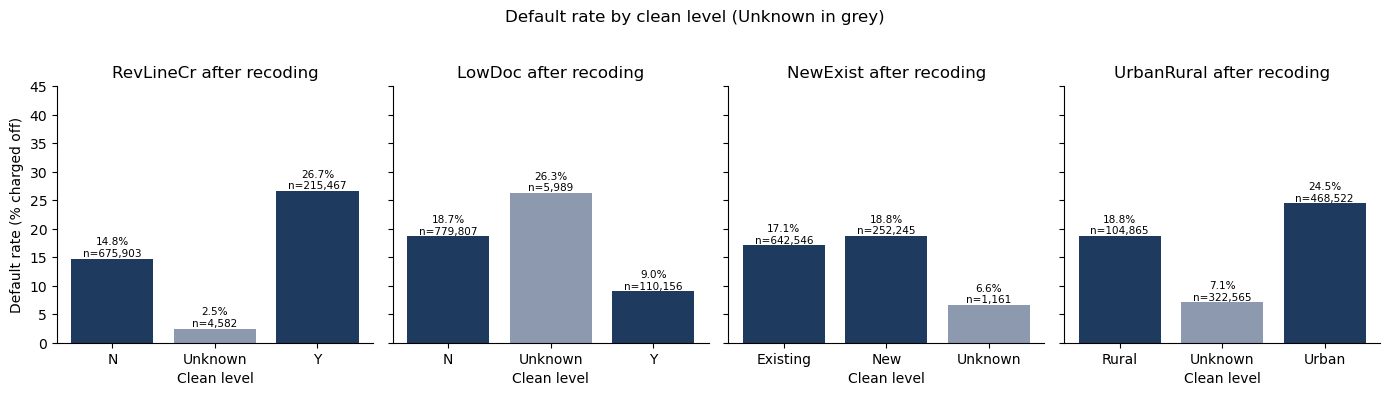

In [12]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.8), sharey=True)
for ax, col in zip(axes, ["RevLineCr", "LowDoc", "NewExist", "UrbanRural"]):
    t = levels.loc[col]
    colours = [P["grey"] if lvl == cl.UNKNOWN else P["navy"] for lvl in t.index]
    ax.bar(t.index, 100 * t["default_rate"], color=colours)
    for x, (rate, n) in enumerate(zip(t["default_rate"], t["loans"])):
        ax.text(x, 100 * rate, f"{100 * rate:.1f}%\nn={n:,}", ha="center", va="bottom", fontsize=7.5)
    ax.set_title(f"{col} after recoding")
    ax.set_xlabel("Clean level")
axes[0].set_ylabel("Default rate (% charged off)")
axes[0].set_ylim(0, 45)
fig.suptitle("Default rate by clean level (Unknown in grey)", y=1.03)
fig.tight_layout()
save_fig(fig, "fig02_default_rate_by_clean_code.png")
plt.show()

The cross-tables confirm every raw code went where we intended, with no code left over. The `Unknown` levels behave very differently from the valid levels: unknown `UrbanRural` loans default at 7.1% against 24.5% for urban, unknown `LowDoc` loans at 26.3% against 18.7% for N, and unknown `NewExist` loans at 6.6% against 17.1% for existing businesses. Filling `UrbanRural` with the mode would move 322,565 loans into the urban group and pull its default rate down from 24.5% to 17.4%, hiding a real difference that a credit officer would want the model to see. For `LowDoc` the mode would barely change the N rate (18.7% to 18.8%) because the group is small, but it would erase a group of 5,989 loans that is clearly riskier. Keeping an explicit level preserves that signal, and notebook 03 tests whether it helps the model.

The cell count reported by `clean_raw()` for this step (around two million) is large because relabelling 1 as `Existing` or `Urban` counts as a changed cell even when the meaning stays the same; the number of loans whose meaning changed is the number of invalid or missing codes shown in the cross-tables.

## 8. Step 5: logical checks

**Decisions.**

* Dates outside 1960 to 2014 are set to missing and the row is flagged with `date_out_of_range`.
* Loans disbursed more than 30 days before approval are kept and flagged with `disb_before_approval`.
* `SBA_Appv` is capped at `GrAppv`.
* `Zip` of 0 becomes missing.
* Loans whose charge-off date disagrees with `MIS_Status` are flagged with `chgoff_mismatch`; `MIS_Status` remains the label.

**Rejected alternatives.** Dropping the early-disbursement loans would remove 133 rows whose other fields look normal, on the strength of one date that may simply be recorded at a different stage of processing. A tolerance of 0 days would flag 805 loans, most of them only a few days early, which is ordinary when a bank advances funds while the guarantee is processed. For the status mismatch we trust `MIS_Status` over `ChgOffDate`, because the status is the field the SBA uses to report the outcome and the date is not used as a feature anyway.

In [13]:
step5 = cl.apply_logical_checks(step4)

# Dates set to missing because they fall outside 1960 to 2014
changed_dates = step5["date_out_of_range"]
print("Out-of-range dates, before and after:")
display(pd.concat({"before": step4.loc[changed_dates, cl.DATE_COLUMNS], "after": step5.loc[changed_dates, cl.DATE_COLUMNS]}, axis=1))

lag = (step5["DisbursementDate"] - step5["ApprovalDate"]).dt.days
print(f"Disbursed before approval: any {(lag < 0).sum()}, more than 30 days {step5['disb_before_approval'].sum()}")
print(f"SBA_Appv above GrAppv: before {(step4['SBA_Appv'] > step4['GrAppv']).sum()}, after {(step5['SBA_Appv'] > step5['GrAppv']).sum()}")
print(f"Zip equal to 0: before {(step4['Zip'] == 0).sum()}, after {(step5['Zip'] == 0).sum()} (missing Zip after: {step5['Zip'].isna().sum()})")
print("Charge-off date versus status (flagged rows):")
pd.crosstab(step5["MIS_Status"], step5["ChgOffDate"].notna().rename("ChgOffDate present"))

Out-of-range dates, before and after:


before                                    after                            
       ApprovalDate DisbursementDate ChgOffDate ApprovalDate DisbursementDate ChgOffDate
54648    1982-08-23       1948-09-17 1991-02-14   1982-08-23              NaT 1991-02-14
379815   2000-03-31       2020-04-14        NaT   2000-03-31              NaT        NaT
598791   1993-09-14       1994-01-31 2026-10-22   1993-09-14       1994-01-31        NaT
642915   2003-06-18       1928-06-18        NaT   2003-06-18              NaT        NaT

Disbursed before approval: any 805, more than 30 days 133
SBA_Appv above GrAppv: before 0, after 0
Zip equal to 0: before 283, after 0 (missing Zip after: 283)
Charge-off date versus status (flagged rows):


ChgOffDate present,False,True
MIS_Status,,
CHGOFF,48,157324
P I F,733658,4922


Three disbursement dates and one charge-off date were impossible and are now missing. 133 loans carry the early-disbursement flag (the two fewer than in notebook 01 left with the removed rows). No guarantee exceeded the loan amount, so the cap changed nothing, but it stays in the pipeline as a safeguard for app inputs. The 283 zero ZIP codes are now missing. The status cross-table shows 4,922 repaid loans with a charge-off date and 48 charged-off loans without one; one more than in notebook 01 because the 2026 charge-off date was set to missing. All 4,970 are flagged and stay in the data with `MIS_Status` as their label.

## 9. Step 6: outliers and impossible values

**Decisions.**

* `NoEmp` of 9999 and values above the 99.9th percentile become missing and are imputed with the median of the same NAICS sector.
* `Term` of 0 months is imputed with the median term of loans in the same size band of `GrAppv`.
* `CreateJob` and `RetainedJob` are capped at their 99.9th percentile.

Each imputation is flagged (`noemp_imputed`, `term_imputed`). The fitted thresholds and medians are returned so the app can apply exactly the same values.

In [14]:
step6, outlier_params = cl.handle_outliers(step5)
print({k: v for k, v in outlier_params.items() if not isinstance(v, dict)})
print("Median Term by loan size band (months):", outlier_params["Term_band_median"])

summary = pd.concat({
    "before": step5[["NoEmp", "Term", "CreateJob", "RetainedJob"]].describe(percentiles=[0.5, 0.999]).T,
    "after": step6[["NoEmp", "Term", "CreateJob", "RetainedJob"]].describe(percentiles=[0.5, 0.999]).T,
})
summary[["mean", "50%", "99.9%", "max"]]

{'NoEmp_cap': 300.0, 'NoEmp_overall_median': 4.0, 'Term_overall_median': 84.0, 'CreateJob_cap': 200.0, 'RetainedJob_cap': 280.0}
Median Term by loan size band (months): {'150k-500k': 120.0, '500k-1m': 240.0, '50k-150k': 84.0, '<50k': 67.0, '>1m': 240.0}


mean    50%   99.9%       max
before NoEmp        11.413  4.000 300.000 9,999.000
       Term        110.914 84.000 309.000   569.000
       CreateJob     8.453  0.000 200.000 8,800.000
       RetainedJob  10.814  1.000 280.000 9,500.000
after  NoEmp        10.125  4.000 205.000   300.000
       Term        110.987 84.000 309.000   569.000
       CreateJob     2.128  0.000 200.000   200.000
       RetainedJob   4.555  1.000 280.000   280.000

In [15]:
print(f"NoEmp values replaced: {step6['noemp_imputed'].sum()} "
      f"(9999 placeholders: {(step5['NoEmp'] == 9999).sum()}, above {outlier_params['NoEmp_cap']:.0f}: "
      f"{((step5['NoEmp'] > outlier_params['NoEmp_cap']) & (step5['NoEmp'] != 9999)).sum()})")
print(f"Term values imputed: {step6['term_imputed'].sum()}")
for col in ["CreateJob", "RetainedJob"]:
    print(f"{col} values capped at {outlier_params[col + '_cap']:.0f}: {(step5[col] > outlier_params[col + '_cap']).sum()}")

# Sector medians used for NoEmp, for the sectors that received most imputations
sector = cl.naics_sector(step6["NAICS"])
used = sector[step6["noemp_imputed"]].value_counts().head(5)
pd.DataFrame({"imputed_loans": used, "median_NoEmp_used": [outlier_params["NoEmp_sector_median"][s] for s in used.index]})

NoEmp values replaced: 884 (9999 placeholders: 4, above 300: 880)
Term values imputed: 802
CreateJob values capped at 200: 870
RetainedJob values capped at 280: 894


,imputed_loans,median_NoEmp_used
NAICS,,
00,377,6.000
56,79,3.000
23,54,5.000
33,53,8.000
62,51,4.000


**Why impute Term rather than drop the rows.** The project plan asks us to show the effect of the alternative. The cell below compares the two.

In [16]:
term0 = step6["term_imputed"]
print(f"Loans with Term 0: {term0.sum()} ({term0.mean():.2%} of rows)")
print(f"Default rate of these loans: {step6.loc[term0, 'Default'].mean():.1%} ({step6.loc[term0, 'Default'].sum()} defaults)")
print(f"Overall default rate keeping them (imputed): {step6['Default'].mean():.2%}")
print(f"Overall default rate if they were dropped:   {step6.loc[~term0, 'Default'].mean():.2%}")
print("Imputed Term values:", step6.loc[term0, "Term"].value_counts().to_dict())

Loans with Term 0: 802 (0.09% of rows)
Default rate of these loans: 91.0% (730 defaults)
Overall default rate keeping them (imputed): 17.56%
Overall default rate if they were dropped:   17.50%
Imputed Term values: {67: 393, 84: 297, 120: 100, 240: 12}


Dropping the 802 Term 0 loans would only remove 0.09% of the rows, but 91.0% of them defaulted, so dropping them would remove 730 defaults and lower the default rate from 17.56% to 17.50%. More importantly, it would remove a group of loans the bank did lend and lose money on. Imputing the size-band median keeps them with a plausible term (most received 67 or 84 months).

There is a caution for notebook 03. Because nearly all Term 0 loans defaulted, the zero was probably written after the loan failed. The `term_imputed` flag therefore carries post-outcome information and must not be used as a feature; we keep it only so that later notebooks can check results with and without these rows.

**Why the sector median for NoEmp.** Firm size differs strongly by industry (a restaurant and a manufacturer of the same loan size employ very different numbers of people), so the sector median is closer to the truth than the overall median of 4. The 99.9th percentile cap of 300 employees is generous for a small business loan and only touches 884 loans. Winsorising the job counts rather than imputing them keeps the information that a loan was linked to many jobs while removing the impossible thousands.

The figure compares the distributions before and after.

Saved docs/figures/fig02_noemp_term_before_after.png


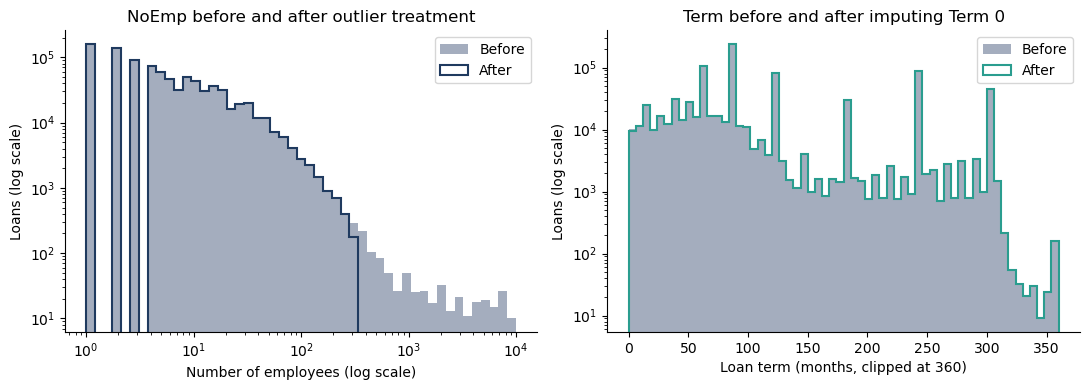

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
bins = np.logspace(0, 4, 50)
axes[0].hist(step5["NoEmp"].clip(lower=1), bins=bins, color=P["grey"], label="Before", alpha=0.8)
axes[0].hist(step6["NoEmp"].clip(lower=1), bins=bins, color=P["navy"], label="After", histtype="step", linewidth=1.5)
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_title("NoEmp before and after outlier treatment")
axes[0].set_xlabel("Number of employees (log scale)")
axes[0].set_ylabel("Loans (log scale)")
axes[0].legend()

term_bins = np.arange(0, 361, 6)
axes[1].hist(step5["Term"].clip(upper=360), bins=term_bins, color=P["grey"], label="Before", alpha=0.8)
axes[1].hist(step6["Term"].clip(upper=360), bins=term_bins, color=P["teal"], label="After", histtype="step", linewidth=1.5)
axes[1].set_yscale("log")
axes[1].set_title("Term before and after imputing Term 0")
axes[1].set_xlabel("Loan term (months, clipped at 360)")
axes[1].set_ylabel("Loans (log scale)")
axes[1].legend()
fig.tight_layout()
save_fig(fig, "fig02_noemp_term_before_after.png")
plt.show()

The long tail of `NoEmp` beyond 300 employees and the spike of loans at 9,999 have gone, while the bulk of the distribution is unchanged. In the `Term` panel the bar at 0 months has disappeared and those loans have moved into the common 60 to 84 month terms. For the bank this means firm size and loan length now hold believable values without distorting the rest of the portfolio.

## 10. Step 7: fill missing text values

**Decision.** A missing `State` is filled from the first three digits of the ZIP code when at least 20 known loans share that prefix and one state accounts for at least 95% of them; otherwise it becomes `Unknown`. Missing `Name`, `City`, `Bank` and `BankState` become `Unknown`.

**Rejected alternatives.** Using the bank's state as the borrower's state would be wrong for out-of-state lending, which is common (it is exactly what the `SameStateBank` feature in notebook 03 measures). Dropping the rows would lose loans for a missing bank name, which is not a reason to doubt the loan itself.

In [18]:
step7 = cl.fill_missing_categoricals(step6)
filled = step6["State"].isna()
print(f"Missing State before: {filled.sum()}, filled from ZIP prefix: {step7['state_from_zip'].sum()}, "
      f"set to Unknown: {(step7['State'] == cl.UNKNOWN).sum()}")
display(pd.DataFrame({"City": step6.loc[filled, "City"], "Zip": step6.loc[filled, "Zip"],
                      "State before": step6.loc[filled, "State"], "State after": step7.loc[filled, "State"]}))
for col in cl.FILL_UNKNOWN_COLUMNS:
    print(f"{col}: missing before {step6[col].isna().sum():,}, after {step7[col].isna().sum()}, "
          f"'Unknown' after {(step7[col] == cl.UNKNOWN).sum():,}")

Missing State before: 13, filled from ZIP prefix: 11, set to Unknown: 2


,City,Zip,State before,State after
49244,JOHNSTOWN NY,<NA>,NaN,Unknown
264664,CAMERON PARK,95682,NaN,CA
306274,"BOX 267, APO AP",96205,NaN,Unknown
328526,WICHITA,67219,NaN,KS
351072,"1542,TABUK,SAUDI ARABIA",79925,NaN,TX
366139,PALM BEACH GARDENS,33410,NaN,FL
366158,CASCO,54205,NaN,WI
367007,SOMERSET,54025,NaN,WI
379174,SALT LAKE CITY,84124,NaN,UT
385418,LAKE OZARK,65049,NaN,MO


Name: missing before 3, after 0, 'Unknown' after 3


City: missing before 30, after 0, 'Unknown' after 30


Bank: missing before 1,505, after 0, 'Unknown' after 1,505
BankState: missing before 1,512, after 0, 'Unknown' after 1,512


Thirteen loans still had a missing state after the earlier steps (one left with the removed rows). Eleven could be filled from the ZIP prefix; the other two have no usable ZIP code or a prefix shared by several states, so they are `Unknown`. The text columns now have no missing values. After this step the only missing values left are `ChgOffDate` (empty by design for repaid loans), 2,171 disbursement dates and the 283 ZIP codes that were 0. We leave the disbursement dates missing rather than guessing them from the approval date: they are needed only for the disbursement lag and recession features in notebook 03, where a missing value can be handled explicitly.

## 11. Step 8: storage types

Text columns with few distinct values (states, banks, cities, the coded columns) are stored as categories and the counts as 32-bit integers. This changes no values but makes the file smaller and faster to load in the app.

In [19]:
clean_steps = cl.optimise_dtypes(step7)
print(f"Memory before: {step7.memory_usage(deep=True).sum() / 1e6:,.0f} MB, after: {clean_steps.memory_usage(deep=True).sum() / 1e6:,.0f} MB")
clean_steps.dtypes.astype(str).value_counts()

Memory before: 724 MB, after: 180 MB


category          10
int32              6
bool               6
float64            5
datetime64[ns]     3
int64              1
object             1
Int64              1
int16              1
int8               1
Name: count, dtype: int64

## 12. The full pipeline in one call

We now run `clean_raw()`, the single entry point that the app and later notebooks use, and check that it produces exactly the same table as the step-by-step run above. The report it returns lists, for each step, the rows before and after and the number of cells changed.

In [20]:
# Free the intermediate tables before running the full pipeline
del step1, step2, step3, step4, step5, step6, step7

clean, report = cl.clean_raw(raw)
assert clean.equals(clean_steps), "clean_raw() differs from the step-by-step result"
print("clean_raw() matches the step-by-step result.")
print("Flag counts:", report["flags"])
report["steps"]

clean_raw() matches the step-by-step result.
Flag counts: {'date_out_of_range': 4, 'disb_before_approval': 133, 'chgoff_mismatch': 4970, 'noemp_imputed': 884, 'term_imputed': 802, 'state_from_zip': 11}


,step,description,rows_before,rows_after,rows_removed,cells_changed,columns_added
0,parse_types,"Currency, dates (century fix) and ApprovalFY p...",899164,899164,0,7353643,
1,add_target,"Loans with unknown MIS_Status dropped, Default...",899164,897167,1997,0,Default
2,remove_near_duplicates,Near-duplicate loans removed,897167,895952,1215,0,
3,clean_codes,"RevLineCr, LowDoc, NewExist, UrbanRural recoded",895952,895952,0,2074891,RevLineCr_raw
4,apply_logical_checks,"Impossible dates, Zip 0, SBA_Appv cap, flags",895952,895952,0,287,"date_out_of_range, disb_before_approval, chgof..."
5,handle_outliers,"NoEmp, Term imputed; job counts winsorised",895952,895952,0,3450,"noemp_imputed, term_imputed"
6,fill_missing_categoricals,State from ZIP prefix; other text to Unknown,895952,895952,0,3063,state_from_zip


Only two steps remove rows: 1,997 loans with unknown outcome and 1,215 near-duplicates, 3,212 rows in total (0.36% of the file). Parsing changes 7.35 million cells because every currency, date and fiscal year value is converted. The later steps change few cells (287 in the logical checks, 3,450 in the outlier step and 3,063 when filling missing text), which is what we want from cleaning: targeted fixes, not a rewrite of the data.

## 13. Quality before and after

The same `quality_assessment()` function from notebook 01 is applied to the raw and the clean table. The 99.9th percentile caps fitted in step 6 are used for both, so the extreme-value lines are measured against the same thresholds.

In [21]:
caps = report["params"]
quality_before = cl.quality_assessment(raw, caps)
quality_after = cl.quality_assessment(clean, caps)
quality = cl.compare_quality(quality_before, quality_after)
quality_path = config.DOCS_DIR / "quality_before_after.csv"
quality.to_csv(quality_path, index=False)
print(f"Saved {rel(quality_path)}")
quality

Saved docs/quality_before_after.csv


,group,check,before,after,change
0,Size,Rows,"899,164.000","895,952.000","-3,212.000"
1,Size,Columns,27.000,35.000,8.000
2,Missing,Missing cells (original 27 columns),"751,248.000","736,160.000","-15,088.000"
3,Missing,Missing cells (% of original cells),3.094,3.043,-0.051
4,Missing,Missing cells excluding ChgOffDate,"14,783.000","2,454.000","-12,329.000"
5,Missing,Rows with unknown MIS_Status,"1,997.000",0.000,"-1,997.000"
6,Format,Numeric or date columns stored as text,9.000,0.000,-9.000
7,Invalid codes,RevLineCr: values outside the code list,"272,951.000",0.000,"-272,951.000"
8,Invalid codes,LowDoc: values outside the code list,"3,425.000",0.000,"-3,425.000"
9,Invalid codes,NewExist: values outside the code list,"1,034.000",0.000,"-1,034.000"


Saved docs/figures/fig02_quality_before_after.png


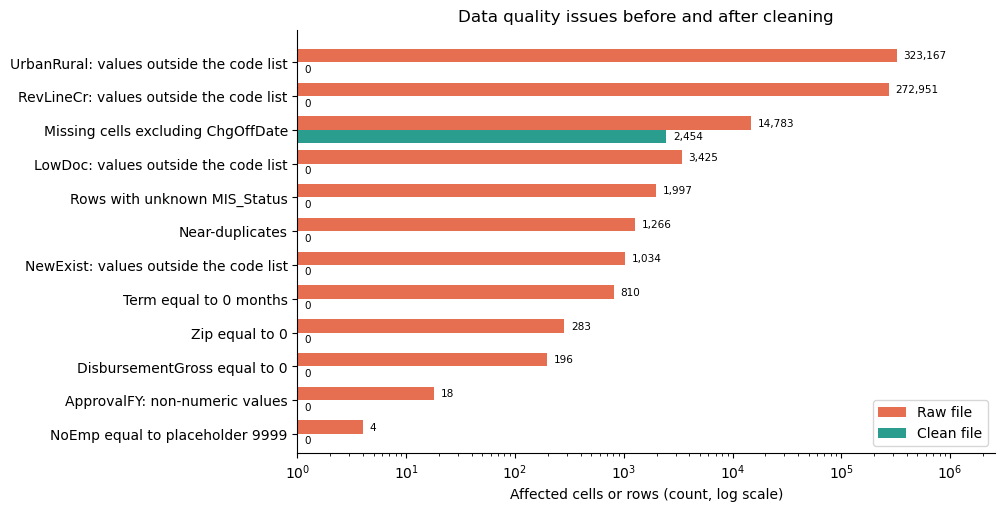

In [22]:
# Chart of the main issue counts before and after cleaning
plot_checks = [
    "UrbanRural: values outside the code list", "RevLineCr: values outside the code list",
    "Missing cells excluding ChgOffDate", "LowDoc: values outside the code list",
    "Rows with unknown MIS_Status", "Near-duplicates (Name, City, State, ApprovalDate, GrAppv)",
    "NewExist: values outside the code list", "Term equal to 0 months", "Zip equal to 0",
    "DisbursementGross equal to 0", "ApprovalFY: non-numeric values", "NoEmp equal to placeholder 9999",
]
q = quality.set_index("check").loc[plot_checks[::-1]]
y = np.arange(len(q))
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(y + 0.2, q["before"], height=0.4, color=P["red"], label="Raw file")
ax.barh(y - 0.2, q["after"].replace(0, np.nan), height=0.4, color=P["teal"], label="Clean file")
for i, (b, a) in enumerate(zip(q["before"], q["after"])):
    ax.text(b * 1.15, i + 0.2, f"{b:,.0f}", va="center", fontsize=7.5)
    ax.text(max(a, 1) * 1.15, i - 0.2, f"{a:,.0f}", va="center", fontsize=7.5)
ax.set_yticks(y)
ax.set_yticklabels([c.replace(" (Name, City, State, ApprovalDate, GrAppv)", "") for c in q.index])
ax.set_xscale("log")
ax.set_xlim(1, q["before"].max() * 8)
ax.set_xlabel("Affected cells or rows (count, log scale)")
ax.set_title("Data quality issues before and after cleaning")
ax.legend(loc="lower right")
save_fig(fig, "fig02_quality_before_after.png")
plt.show()

Saved docs/figures/fig02_missing_before_after.png


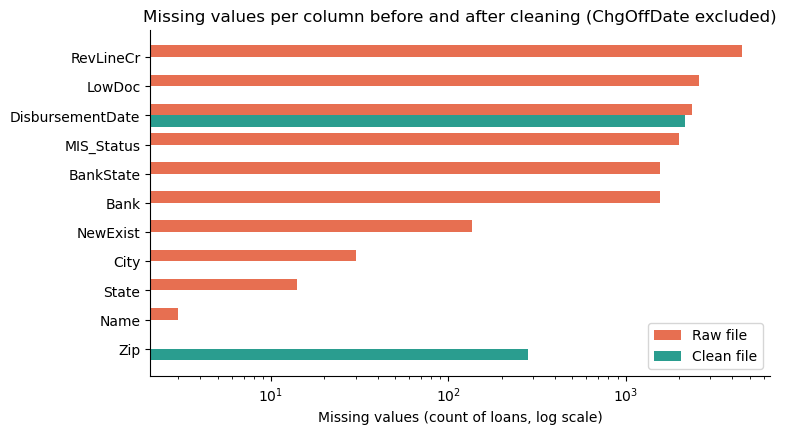

,before,after
Zip,0,283
Name,3,0
State,14,0
City,30,0
NewExist,136,0
Bank,1559,0
BankState,1566,0
MIS_Status,1997,0
DisbursementDate,2368,2171
LowDoc,2582,0


In [23]:
# Missing cells per original column, before and after
miss = pd.DataFrame({"before": raw.isna().sum(), "after": clean[raw.columns].isna().sum()})
miss = miss[(miss["before"] > 0) | (miss["after"] > 0)].drop(index="ChgOffDate").sort_values("before")
fig, ax = plt.subplots(figsize=(8, 4.5))
yy = np.arange(len(miss))
ax.barh(yy + 0.2, miss["before"], height=0.4, color=P["red"], label="Raw file")
ax.barh(yy - 0.2, miss["after"].replace(0, np.nan), height=0.4, color=P["teal"], label="Clean file")
ax.set_yticks(yy)
ax.set_yticklabels(miss.index)
ax.set_xscale("log")
ax.set_xlabel("Missing values (count of loans, log scale)")
ax.set_title("Missing values per column before and after cleaning (ChgOffDate excluded)")
ax.legend(loc="lower right")
save_fig(fig, "fig02_missing_before_after.png")
plt.show()
miss

Every invalid code, impossible value, format problem and near-duplicate counted in notebook 01 is now at zero. Missing cells outside `ChgOffDate` fall from 14,783 to 2,454, and the ones left are disbursement dates and ZIP codes that we chose not to guess. The logical lines are the exception by design: the 133 early disbursements and the 4,970 status mismatches are still in the data, now flagged, because the evidence did not justify removing them. The table grows from 27 to 35 columns: `Default`, `RevLineCr_raw` and six flag columns.

## 14. Save the clean table

The clean file keeps the post-outcome columns (`ChgOffDate`, `ChgOffPrinGr`, `BalanceGross`, `MIS_Status`) and the identifiers so that later notebooks can run checks, for example confirming that `Default` matches `MIS_Status`. They must never be used as features: every later notebook removes `config.LEAKAGE_COLUMNS` and `config.IDENTIFIER_COLUMNS` before modelling, and the same applies to the flag `term_imputed` for the reason given in section 9.

In [24]:
clean.to_parquet(config.CLEAN_DATA_PATH, index=False)
check = pd.read_parquet(config.CLEAN_DATA_PATH)
assert check.shape == clean.shape and (check["Default"] == clean["Default"]).all()
print(f"Saved {rel(config.CLEAN_DATA_PATH)}: {check.shape[0]:,} rows, {check.shape[1]} columns, "
      f"{config.CLEAN_DATA_PATH.stat().st_size / 1e6:,.1f} MB")
print(f"Default rate in the clean table: {check['Default'].mean():.2%} "
      f"({check['Default'].sum():,} defaults of {len(check):,} loans)")
print("Leakage columns kept for checks only:", [c for c in config.LEAKAGE_COLUMNS if c in check.columns])
print("Identifier columns kept for checks only:", [c for c in config.IDENTIFIER_COLUMNS if c in check.columns])

Saved data/processed/loans_clean.parquet: 895,952 rows, 35 columns, 43.6 MB
Default rate in the clean table: 17.56% (157,372 defaults of 895,952 loans)
Leakage columns kept for checks only: ['ChgOffDate', 'ChgOffPrinGr', 'BalanceGross', 'MIS_Status']
Identifier columns kept for checks only: ['LoanNr_ChkDgt', 'Name']


## 15. Cleaning log

Finally we write `docs/cleaning_log.md`, a dated record of every issue, the decision taken, the reason, and the rows or cells affected. All numbers in the log are computed from the tables above, so the log cannot drift from the data.

In [25]:
q = quality.set_index("check")
steps = report["steps"].set_index("step")
flags = report["flags"]
params = report["params"]


def qb(check):
    """Raw-file count for a quality check, as text."""
    return f"{q.loc[check, 'before']:,.0f}"


rev_counts = raw["RevLineCr"].value_counts(dropna=False)
log_rows = [
    ("Currency columns stored as text", "Strip $, commas and spaces; convert to float",
     "Amounts must be numeric for every later calculation", "5 columns, all rows"),
    ("Dates as dd-Mon-yy text with two-digit years", "Explicit format and century rule (years above the current two digits are 19xx)",
     "Python's default rule put 9 approvals from the 1960s in the 2060s", "3 columns, all non-empty values"),
    ("ApprovalFY text with '1976A'", "Strip non-digits, store as integer", "Fiscal year is a number", f"{qb('ApprovalFY: non-numeric values')} rows"),
    ("MIS_Status missing", "Drop rows; create Default (1 = CHGOFF, 0 = P I F)",
     "Outcome unknown; imputing it would invent the label", f"{steps.loc['add_target', 'rows_removed']:,} rows removed"),
    ("DisbursementGross equal to 0", "No separate rule", "All such loans had unknown status and were removed with them",
     f"{qb('DisbursementGross equal to 0')} rows (within the rows above)"),
    ("Near-duplicate loans (Name, City, State, ApprovalDate, GrAppv)", "Keep the first of each group",
     "Prevents one borrower decision appearing in both training and test data",
     f"{steps.loc['remove_near_duplicates', 'rows_removed']:,} rows removed"),
    ("RevLineCr codes 0, T, 16 rare codes and missing", "0 to N, T to Y, others to Unknown; raw code kept in RevLineCr_raw",
     "0 matches N and T matches Y on amount, term, guarantee share and redraw pattern (notebook 01)",
     f"{rev_counts.get('0', 0):,} coded 0, {rev_counts.get('T', 0):,} coded T, {(clean['RevLineCr'] == 'Unknown').sum():,} Unknown after cleaning"),
    ("LowDoc codes 0, C, S, A, R, 1 and missing", "Y and N kept, others to Unknown",
     "No code matches Y or N; unknown group has a distinct default rate", f"{(clean['LowDoc'] == 'Unknown').sum():,} Unknown after cleaning"),
    ("NewExist 0 and missing", "1 Existing, 2 New, others Unknown", "Unknown group defaults far less than either valid group",
     f"{(clean['NewExist'] == 'Unknown').sum():,} Unknown after cleaning"),
    ("UrbanRural 0 (undefined)", "1 Urban, 2 Rural, 0 Unknown", "Unknown group (mostly older loans) defaults at a third of the urban rate; mode imputation would hide this",
     f"{(clean['UrbanRural'] == 'Unknown').sum():,} Unknown after cleaning"),
    ("Dates outside 1960 to 2014", "Set to missing, flag date_out_of_range", "Typing errors outside the period covered", f"{flags['date_out_of_range']} rows"),
    ("Disbursement more than 30 days before approval", "Keep, flag disb_before_approval", "Other fields look normal; date may be recorded at another stage",
     f"{flags['disb_before_approval']} rows flagged"),
    ("SBA_Appv above GrAppv", "Cap at GrAppv", "Guarantee cannot exceed the loan; safeguard for app inputs", f"{qb('SBA_Appv above GrAppv')} rows"),
    ("Zip equal to 0", "Set to missing", "Not a valid ZIP code", f"{qb('Zip equal to 0')} cells"),
    ("ChgOffDate disagrees with MIS_Status", "Keep MIS_Status as label, flag chgoff_mismatch", "Status is the reported outcome; ChgOffDate is post-outcome and never a feature",
     f"{flags['chgoff_mismatch']:,} rows flagged"),
    ("NoEmp 9999 and above the 99.9th percentile", f"Set to missing, impute NAICS sector median, flag noemp_imputed (cap {params['NoEmp_cap']:.0f})",
     "Placeholder and impossible head counts; firm size depends on sector", f"{flags['noemp_imputed']} cells"),
    ("Term equal to 0 months", "Impute median Term of the loan-size band, flag term_imputed",
     "Keeps 802 mostly defaulted loans; flag is post-outcome and must not be a feature", f"{flags['term_imputed']} cells"),
    ("CreateJob, RetainedJob extremes", f"Winsorise at 99.9th percentile ({params['CreateJob_cap']:.0f} and {params['RetainedJob_cap']:.0f})",
     "Thousands of jobs per small loan are entry errors",
     " and ".join(f"{quality.loc[quality['check'].str.startswith(c + ' above'), 'before'].iloc[0]:,.0f} {c}" for c in ["CreateJob", "RetainedJob"]) + " values capped"),
    ("State missing", "Fill from three-digit ZIP prefix when one state has at least 95% of 20 or more loans, else Unknown",
     "Bank state differs from borrower state for out-of-state lending", f"{flags['state_from_zip']} filled, {(clean['State'] == 'Unknown').sum()} Unknown"),
    ("Name, City, Bank, BankState missing", "Fill with Unknown", "Missing text is not a reason to drop a loan",
     ", ".join(f"{c} {raw[c].isna().sum():,}" for c in cl.FILL_UNKNOWN_COLUMNS)),
    ("NAICS 0, FranchiseCode 0 and 1", "No change in cleaning", "Handled as Unknown sector and IsFranchise in notebook 03", "no cells changed"),
    ("Post-outcome columns", "Kept in the file, excluded from features via config.LEAKAGE_COLUMNS",
     "Needed for checks only", "ChgOffDate, ChgOffPrinGr, BalanceGross, MIS_Status"),
]


def md_table(header, rows):
    """Small helper that renders a list of rows as a Markdown table."""
    lines = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    lines += ["| " + " | ".join(str(x) for x in r) + " |" for r in rows]
    return "\n".join(lines)


step_rows = [(i + 1, r.step, r.description, f"{r.rows_before:,}", f"{r.rows_after:,}", f"{r.rows_removed:,}", f"{r.cells_changed:,}")
             for i, r in enumerate(report["steps"].itertuples())]
fmt = lambda v: f"{v:,.3f}" if float(v) % 1 else f"{v:,.0f}"
quality_rows = [(r.group, r.check, fmt(r.before), fmt(r.after), fmt(r.change)) for r in quality.itertuples()]

log = f"""# Cleaning log

Date: {date.today():%d %B %Y}
Author: Salem Adel Salem Alshamlan Almarri
Produced by: notebooks/02_data_cleaning.ipynb using src/cleaning.py
Input: data/raw/SBAnational.csv ({len(raw):,} rows, {raw.shape[1]} columns)
Output: data/processed/loans_clean.parquet ({len(clean):,} rows, {clean.shape[1]} columns)

## Summary

{len(raw) - len(clean):,} rows were removed ({100 * (len(raw) - len(clean)) / len(raw):.2f}% of the raw file): {steps.loc['add_target', 'rows_removed']:,} with unknown outcome and {steps.loc['remove_near_duplicates', 'rows_removed']:,} near-duplicates. The default rate of the clean table is {clean['Default'].mean():.2%}. Missing cells outside ChgOffDate fell from {q.loc['Missing cells excluding ChgOffDate', 'before']:,.0f} to {q.loc['Missing cells excluding ChgOffDate', 'after']:,.0f}. All invalid codes and impossible values counted in the raw file are zero after cleaning; flagged logical inconsistencies are kept on purpose.

## Issues and decisions

{md_table(["No.", "Issue", "Decision", "Reason", "Rows or cells affected"], [(i + 1, *r) for i, r in enumerate(log_rows)])}

## Rows and cells changed by each step

{md_table(["Step", "Function", "What it does", "Rows before", "Rows after", "Rows removed", "Cells changed"], step_rows)}

Cells changed counts every value that differs from the previous step, including type conversions and relabelling (for example 1 to Urban), so it is larger than the number of loans whose meaning changed.

## Quality before and after

{md_table(["Group", "Check", "Raw file", "Clean file", "Change"], quality_rows)}

The same table is saved as docs/quality_before_after.csv.
"""
log_path = config.DOCS_DIR / "cleaning_log.md"
log_path.write_text(log, encoding="utf-8")
print(f"Saved {rel(log_path)} ({len(log.splitlines())} lines)")
print(log[:1500])

Saved docs/cleaning_log.md (86 lines)
# Cleaning log

Date: 22 November 2026
Author: Salem Adel Salem Alshamlan Almarri
Produced by: notebooks/02_data_cleaning.ipynb using src/cleaning.py
Input: data/raw/SBAnational.csv (899,164 rows, 27 columns)
Output: data/processed/loans_clean.parquet (895,952 rows, 35 columns)

## Summary

3,212 rows were removed (0.36% of the raw file): 1,997 with unknown outcome and 1,215 near-duplicates. The default rate of the clean table is 17.56%. Missing cells outside ChgOffDate fell from 14,783 to 2,454. All invalid codes and impossible values counted in the raw file are zero after cleaning; flagged logical inconsistencies are kept on purpose.

## Issues and decisions

| No. | Issue | Decision | Reason | Rows or cells affected |
|---|---|---|---|---|
| 1 | Currency columns stored as text | Strip $, commas and spaces; convert to float | Amounts must be numeric for every later calculation | 5 columns, all rows |
| 2 | Dates as dd-Mon-yy text with two-digit y

## 16. Summary

The clean table has 895,952 loans and 35 columns, with a default rate of 17.56%. Only 3,212 rows were removed, and each removal has a clear reason: an unknown outcome or a near-duplicate. Everything else was repaired in place, and every repair that involved a judgement is visible through a flag column or the `RevLineCr_raw` code, so notebook 03 can test our choices rather than inherit them silently.

Three points carry forward. The `Unknown` levels of `UrbanRural`, `LowDoc` and `NewExist` have default rates that differ clearly from the valid levels and should be tested as features. The `term_imputed` flag is post-outcome information and must stay out of the model, along with `config.LEAKAGE_COLUMNS`. And the low default rates of loans approved after 2010 are a censoring effect, not a sign of better borrowers, which notebook 05 addresses with a temporal validation.